<a href="https://colab.research.google.com/github/dany-echeverria/PIA_PPIA_V2_9201/blob/main/AF2_PPIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PpIA:ACTIVIDAD FUNDAMENTAL 2**



Grupo:01

Carrera :IIA

NOMBRES:  / MATRICULA:

Gael Sebastián García Azpeytia / 2164681

Michelle Fernanda Blanco Martínez / 2182171

Alexandra Diaz Sandria / 2276207

Mayté Mendoza Sánchez / 2189263

Daniel Alejandro García Echeverría / 2163681


Ejercicio 1 Uso de Pandas, Mathplotlib y Numpy

Utilizamos el Dataset de Calidad de Vino (Wine Quality Dataset) del repositorio UCI.

Limpieza y manipulación con Pandas

Empezamos importando todas las librerias que ocuparemos para el ejercicio como **pandas** para manupulacion de datos, **numpy** para procedimientos matemáticos como matrices y probabilidad y finalmente **matplotlib** para visualización de datos en forma de gráficos.
 Despúes colocamos el url que usaremos en este caso de una vineria;Al finalizar, unicamente mostramos los primeros 5 datos utilizando la funcion df.head() y describimos sus caracteriasticas con la función df.describe() .


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
print(df.head(5))
print("¡Dataset cargado con éxito!")
print(df.info())
print(df.describe())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

Identificamos y eliminamos los valores nulos

In [ ]:
print("Valores nulos por columna:")
print(df.isnull().sum())
df_limpio = df.dropna().copy()
print(f"Filas totales después de eliminar nulos: {df_limpio.shape[0]}")

Valores nulos por columna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Filas totales después de eliminar nulos: 1599


Creamos una nueva columna llamada is_good que sea 1 si la quality es mayor a 6, y 0 en caso contrario.

In [ ]:
df_limpio['is_good'] = np.where(df_limpio['quality'] > 6, 1, 0)
df_alcoholalto = df_limpio[df_limpio['alcohol'] > 11.0]
print(f"Cantidad de vinos clasificados como 'is_good': {df_limpio['is_good'].sum()}")
print(f"Cantidad de vinos con alcohol > 11%: {len(df_alcoholalto)}")

Cantidad de vinos clasificados como 'is_good': 217
Cantidad de vinos con alcohol > 11%: 408


Mostramos el DataFrame con los resultados de un nivel superior de alcohol del 11%

In [ ]:
print("DataFrame filtrado (Alcohol > 11%) ")
display(df_alcoholalto.head())
alcohol_promedio_por_calidad = df_limpio.groupby('is_good')['alcohol'].mean()
print("\nNivel de alcohol medio según la categoría 'is_good':")
print(alcohol_promedio_por_calidad)

DataFrame filtrado (Alcohol > 11%) 


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
45,4.6,0.52,0.15,2.1,0.054,8.0,65.0,0.9934,3.90,0.56,13.1,4,0
95,4.7,0.60,0.17,2.3,0.058,17.0,106.0,0.9932,3.85,0.60,12.9,6,0
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6,0



Nivel de alcohol medio según la categoría 'is_good':
is_good
0    10.251037
1    11.518049
Name: alcohol, dtype: float64


1.2 Operaciones matemáticas con Numpy

Convertimos el dataframe de features en un matriz "X" y mostramos las primeras 5 filas de la matriz.

In [ ]:
features = df_limpio.drop(columns=['quality', 'is_good'])
X = features.to_numpy()
print("\nForma de la matriz X (filas, columnas):", X.shape)
print("Primeras 5 filas de la matriz X:\n", X[:5])


Forma de la matriz X (filas, columnas): (1599, 11)
Primeras 5 filas de la matriz X:
 [[7.400e+00 7.000e-01 0.000e+00 1.900e+00 7.600e-02 1.100e+01 3.400e+01
  9.978e-01 3.510e+00 5.600e-01 9.400e+00]
 [7.800e+00 8.800e-01 0.000e+00 2.600e+00 9.800e-02 2.500e+01 6.700e+01
  9.968e-01 3.200e+00 6.800e-01 9.800e+00]
 [7.800e+00 7.600e-01 4.000e-02 2.300e+00 9.200e-02 1.500e+01 5.400e+01
  9.970e-01 3.260e+00 6.500e-01 9.800e+00]
 [1.120e+01 2.800e-01 5.600e-01 1.900e+00 7.500e-02 1.700e+01 6.000e+01
  9.980e-01 3.160e+00 5.800e-01 9.800e+00]
 [7.400e+00 7.000e-01 0.000e+00 1.900e+00 7.600e-02 1.100e+01 3.400e+01
  9.978e-01 3.510e+00 5.600e-01 9.400e+00]]


In [ ]:
features = df_limpio.drop(columns=['quality', 'is_good'])
X = features.to_numpy()
print("1. Matriz X creada con éxito.")
print("Forma de la matriz X (filas, columnas):", X.shape)

1. Matriz X creada con éxito.
Forma de la matriz X (filas, columnas): (1599, 11)


Calculamos la media y la dezsviación estandar utilizando Numpy utilizando np.mean para (mu) y np.std para (sigma)

In [ ]:
mu = np.mean(X, axis=0)
sigma = np.std(X, axis=0)
print(" Cálculos de NumPy realizados:")
print("Media (mu)de cada columna:\n", mu)
print("Desviación estándar (sigma) de cada columna:\n", sigma)

 Cálculos de NumPy realizados:
Media (mu)de cada columna:
 [ 8.31963727  0.52782051  0.27097561  2.5388055   0.08746654 15.87492183
 46.46779237  0.99674668  3.3111132   0.65814884 10.42298311]
Desviación estándar (sigma) de cada columna:
 [1.74055180e+00 1.79003704e-01 1.94740214e-01 1.40948711e+00
 4.70505826e-02 1.04568856e+01 3.28850367e+01 1.88674370e-03
 1.54338181e-01 1.69453967e-01 1.06533430e+00]


Normalizamos en Z-score implementando la formula manualmente donde $x$ es el valor original, $\mu$ la media y $\sigma$ la desviación estándar, mostrando las primeras 5 columnas y verificando la normalización donde las medias deberian aproximarse a 0 (cero) y la desviación estandar a 1

In [ ]:
Z = (X - mu) / sigma
print("Normalización Z-Score aplicada con éxito.")
print("Muestra de los datos normalizados (primeras 5 filas)")
print(Z[:5])
print("\nVerificación post-normalización:")
print("Medias (deben ser cercanas a 0):", np.round(np.mean(Z, axis=0), 5))
print("Desviación estándar (deben ser 1):", np.round(np.std(Z, axis=0), 5))

Normalización Z-Score aplicada con éxito.
Muestra de los datos normalizados (primeras 5 filas)
[[-0.52835961  0.96187667 -1.39147228 -0.45321841 -0.24370669 -0.46619252
  -0.37913269  0.55827446  1.28864292 -0.57920652 -0.96024611]
 [-0.29854743  1.96744245 -1.39147228  0.04341614  0.2238752   0.87263823
   0.62436323  0.02826077 -0.7199333   0.1289504  -0.58477711]
 [-0.29854743  1.29706527 -1.18607043 -0.16942723  0.09635286 -0.08366945
   0.22904665  0.13426351 -0.33117661 -0.04808883 -0.58477711]
 [ 1.65485608 -1.38444349  1.4841536  -0.45321841 -0.26496041  0.10759209
   0.41150046  0.6642772  -0.97910442 -0.46118037 -0.58477711]
 [-0.52835961  0.96187667 -1.39147228 -0.45321841 -0.24370669 -0.46619252
  -0.37913269  0.55827446  1.28864292 -0.57920652 -0.96024611]]

Verificación post-normalización:
Medias (deben ser cercanas a 0): [ 0.  0. -0. -0.  0. -0.  0. -0.  0.  0.  0.]
Desviación estándar (deben ser 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


1.3 Visualización de insight con Matplotlib

Visualizamos los datos sobre el porcentaje de alcohol de los vinos en forma de un Histograma

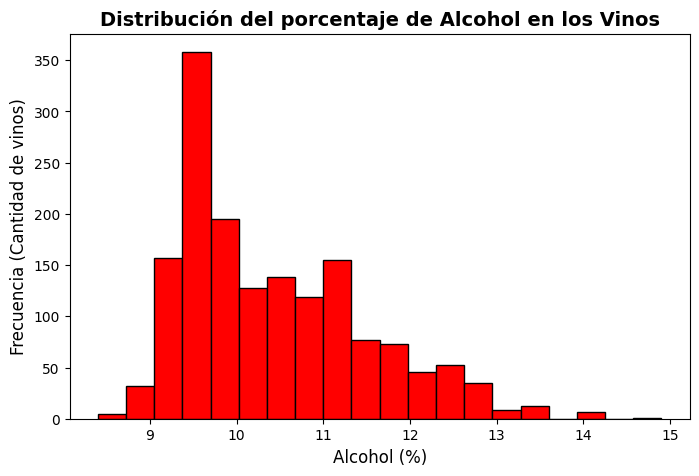

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df_limpio['alcohol'], bins=20, color='red', edgecolor='black')
plt.title('Distribución del porcentaje de Alcohol en los Vinos', fontsize=14, fontweight='bold')
plt.xlabel('Alcohol (%)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de vinos)', fontsize=12)
plt.show()

Gráfico de dispersión entre ph y fixed acidity observando que medida que aumenta la acidez fija (fixed acidity), el valor del pH disminuye,lo cual tiene sentido en la parte quimica ya que una mayor concentración de ácido vuelve la solución más ácida (pH más bajo)."

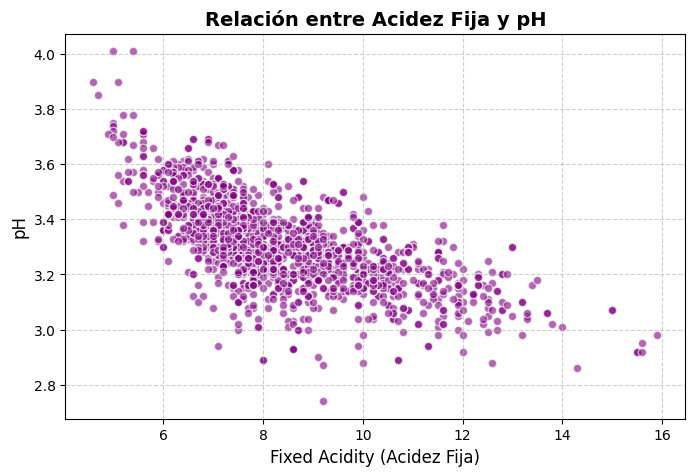

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df_limpio['fixed acidity'], df_limpio['pH'], color='purple', alpha=0.6, edgecolors='w')
plt.title('Relación entre Acidez Fija y pH', fontsize=14, fontweight='bold')
plt.xlabel('Fixed Acidity (Acidez Fija)', fontsize=12)
plt.ylabel('pH', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Generamos un gráfico de cajas (boxplot) comparando el nivel de alchol segín la calidad (quality).

<Figure size 1000x600 with 0 Axes>

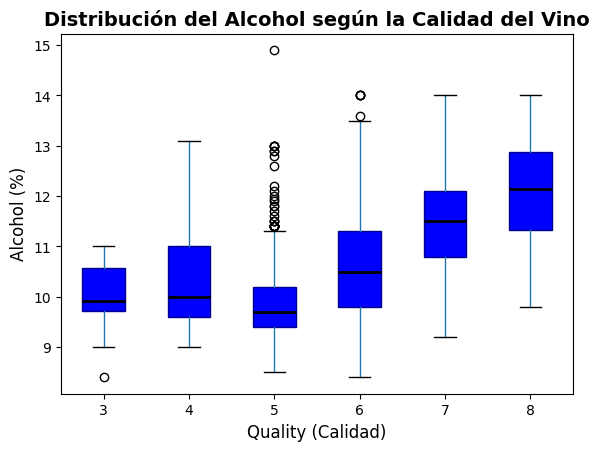

In [ ]:
plt.figure(figsize=(10, 6))
df_limpio.boxplot(column='alcohol', by='quality', grid=False, patch_artist=True,
                  boxprops=dict(facecolor='blue', color='darkblue'),
                  medianprops=dict(color='black', linewidth=2))
plt.title('Distribución del Alcohol según la Calidad del Vino', fontsize=14, fontweight='bold')
plt.suptitle('')
plt.xlabel('Quality (Calidad)', fontsize=12)
plt.ylabel('Alcohol (%)', fontsize=12)
plt.show()

Ejercicio 2

Utilizamos el conjunto de datos Pingüinos de Palmer (Palmer Penguins).


En esta celda se importan las librerías esenciales para el análisis de datos. Posteriormente, se define la URL pública del dataset de los pingüinos de Palmer alojado, se carga mediante un DataFrame de Pandas y se visualizan los primeros registros para confirmar que los datos se importaron de forma correcta.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# URL del dataset de pingüinos de Palmer
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

# Cargar los datos
df = pd.read_csv(url)

# Mostrar los primeros registros para confirmar
print("Dataset cargado correctamente:")
display(df.head())

Dataset cargado correctamente:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### Ejercicio 2.1

1. **Limpieza de nulos:** Se analizan los valores faltantes del dataset y se filtran eliminando filas que carecen de información
2. **Agrupación:** Se utiliza el método `groupby` para calcular la masa corporal promedio por cada especie y por cada isla.
3. **Segmentación:** Se crea un subconjunto filtrando específicamente a los pingüinos de la especie "Gentoo" que superan los 5000g de peso.

In [ ]:
# 1 y 2. Ver nulos y limpiar filas críticas
print("Valores nulos en el dataset:")
print(df.isnull().sum())

# Creamos un dataframe limpio eliminando nulos en columnas clave
df_clean = df.dropna(subset=['body_mass_g', 'bill_length_mm', 'bill_depth_mm']).copy()

# 3. Agrupación por especie e isla calculando el promedio de peso
print("\n--- Masa corporal promedio por especie e isla ---")
promedio_masa = df_clean.groupby(['species', 'island'])['body_mass_g'].mean().reset_index()
display(promedio_masa)

# 4. Segmentación: Especie "Gentoo" con peso mayor a 5000g
gentoo_pesados = df_clean[(df_clean['species'] == 'Gentoo') & (df_clean['body_mass_g'] > 5000)]
print(f"\n--- Pingüinos Gentoo de más de 5000g (Total encontrados: {len(gentoo_pesados)}) ---")
display(gentoo_pesados.head())

Valores nulos en el dataset:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

--- Masa corporal promedio por especie e isla ---


,species,island,body_mass_g
0,Adelie,Biscoe,3709.659091
1,Adelie,Dream,3688.392857
2,Adelie,Torgersen,3706.372549
3,Chinstrap,Dream,3733.088235
4,Gentoo,Biscoe,5076.016260



--- Pingüinos Gentoo de más de 5000g (Total encontrados: 61) ---


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
227,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,MALE
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,MALE


### Ejercicio 2.2

1. **Transformación a matriz:** Se extraen las columnas del largo y alto del pico para convertirlas en una matriz bidimensional

2. **Cálculo de proporción:** Se calcula el vector del largo entre el alto para cada pingüino.

3. **Detección de outliers:** Se calcula la media y la desviación estándar del largo del pico empleando funciones de NumPy para aislar los valores

4. **Slicing:** Se seleccionan únicamente los registros ubicados en las posiciones pares del array original mediante indexación.

In [ ]:
# 1. Extraer columnas a matriz NumPy de N x 2
pico_matriz = df_clean[['bill_length_mm', 'bill_depth_mm']].to_numpy()
print("Dimensiones de la matriz:", pico_matriz.shape)

# 2. Cálculo de proporción (Largo / Alto)
largo = pico_matriz[:, 0]
alto = pico_matriz[:, 1]
proporcion = largo / alto
print("Primeros valores de la proporción:", proporcion[:5])

# 3. Detección de outliers (más de 2 desviaciones estándar de la media)
media_largo = np.mean(largo)
desv_std_largo = np.std(largo)
outliers = np.abs(largo - media_largo) > (2 * desv_std_largo)
print(f"Cantidad de outliers en el largo del pico: {np.sum(outliers)}")

# 4. Slicing para obtener posiciones pares (índices 0, 2, 4, 6...)
pico_pares = pico_matriz[::2]
print("Dimensiones del array con posiciones pares:", pico_pares.shape)

Dimensiones de la matriz: (342, 2)
Primeros valores de la proporción: [2.09090909 2.27011494 2.23888889 1.9015544  1.90776699]
Cantidad de outliers en el largo del pico: 6
Dimensiones del array con posiciones pares: (171, 2)


### Ejercicio 2.3
1. **Gráfico de dispersión:** Se grafica la longitud de las aletas en el eje X frente a la masa corporal en el eje Y.

2. **Codificación por colores:** Se asigna un color único a cada especie (Adelie, Chinstrap y Gentoo) para visualizar sus agrupamientos naturales.

3. **Anotaciones:** Se identifica el índice del pingüino más pesado del dataset mediante Pandas y se inserta una etiqueta con flecha señalando directamente su posición.

4. **Layout de Subplots:** Se estructura una figura con paneles múltiples para mostrar de forma paralela los histogramas de distribución de la masa corporal y del tamaño de aletas.

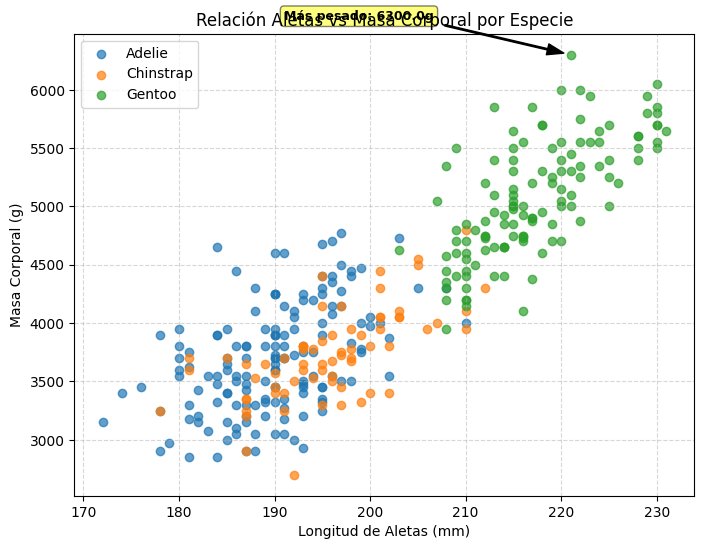

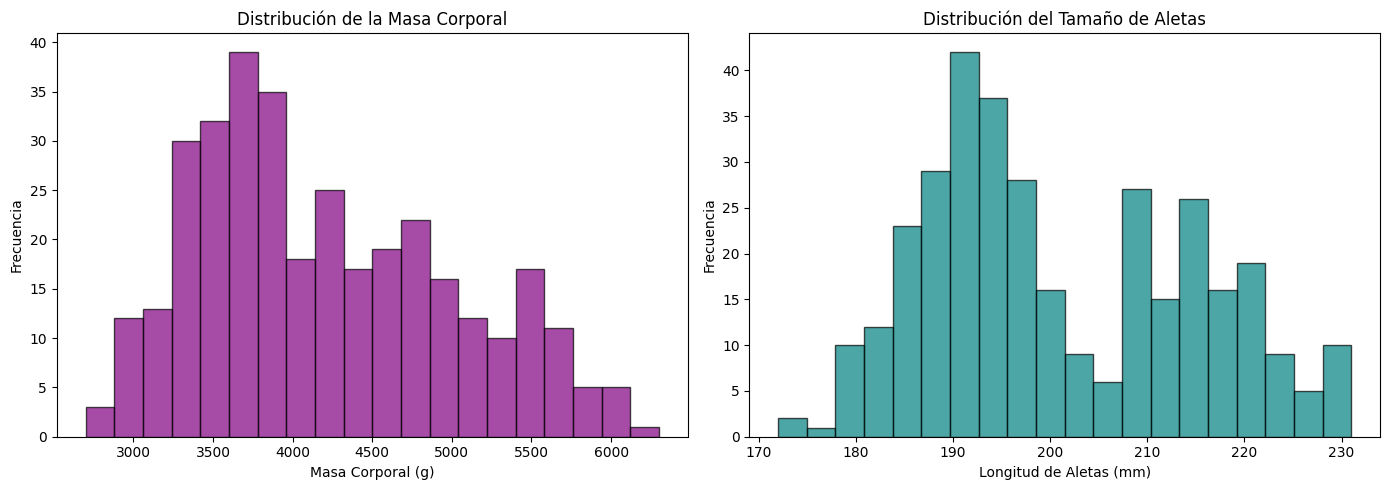

In [ ]:
# 1 y 2. Gráfico de dispersión (Scatter Plot) con colores por especie
fig, ax = plt.subplots(figsize=(8, 6))

especies = df_clean['species'].unique()
colores = {'Adelie': 'tab:blue', 'Chinstrap': 'tab:orange', 'Gentoo': 'tab:green'}

for especie in especies:
    subset = df_clean[df_clean['species'] == especie]
    ax.scatter(subset['flipper_length_mm'], subset['body_mass_g'],
               label=especie, color=colores.get(especie, 'gray'), alpha=0.7)

# 3. Anotar al pingüino más pesado
idx_max_peso = df_clean['body_mass_g'].idxmax()
pingüino_pesado = df_clean.loc[idx_max_peso]

ax.annotate(f"Más pesado: {pingüino_pesado['body_mass_g']}g",
            xy=(pingüino_pesado['flipper_length_mm'], pingüino_pesado['body_mass_g']),
            xytext=(pingüino_pesado['flipper_length_mm'] - 30, pingüino_pesado['body_mass_g'] + 300),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
            fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

ax.set_title("Relación Aletas vs Masa Corporal por Especie")
ax.set_xlabel("Longitud de Aletas (mm)")
ax.set_ylabel("Masa Corporal (g)")
ax.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Layout con dos Subplots (Histogramas comparativos)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(df_clean['body_mass_g'], bins=20, color='purple', edgecolor='black', alpha=0.7)
ax1.set_title("Distribución de la Masa Corporal")
ax1.set_xlabel("Masa Corporal (g)")
ax1.set_ylabel("Frecuencia")

ax2.hist(df_clean['flipper_length_mm'], bins=20, color='teal', edgecolor='black', alpha=0.7)
ax2.set_title("Distribución del Tamaño de Aletas")
ax2.set_xlabel("Longitud de Aletas (mm)")
ax2.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()